# ELEC2

Online conformal prediction of electricity transfer using a fixed gradient-boosted regressor.


In [1]:
# Locate the project root.
from pathlib import Path
import sys
_PROJECT_CANDIDATES = (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent)
PROJECT_ROOT = next((p for p in _PROJECT_CANDIDATES if (p / "cp_methods.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the project directory.")
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_DIR = PROJECT_ROOT / "data"

import contextlib
from functools import partial
from importlib.metadata import version
import io
from pathlib import Path
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

import cp_methods as cpm

DATA_PATH = DATA_DIR / "electricity-normalized.csv"
COVARIATES = ["nswprice", "nswdemand", "vicprice", "vicdemand"]
RESPONSE = "transfer"
REMOVE_INITIAL = 17_760
TRAIN_FRAC = 0.70
ALPHA = 0.10
R = 100
SEED = 42
BOOT_BLOCK_LEN = 48
BOOT_REPS = 1_000
ROLLING_WINDOW = 48 * 7
SPCI_W_LAG = 24
SPCI_T_TRAIN = R
SPCI_REFIT_EVERY = 24
# One worker and one numerical thread give all methods the same CPU budget.
N_THREADS = 1

METHOD_ORDER = ["cp", "lcp", "aci", "dtaci", "cop", "lqt", "spci", "olcp", "olcph"]
LABELS = {
    "cp": "CP", "lcp": "LCP", "aci": "ACI", "dtaci": "DtACI",
    "cop": "COP", "lqt": "LQT", "spci": "SPCI",
    "olcp": "OLCP", "olcph": "OLCP-Hedge",
}
# Run SPCI last.
METHOD_RUNNERS = {
    "cp": cpm.eval_cp,
    "cop": cpm.eval_cop,
    "lqt": cpm.eval_lqt,
    "lcp": cpm.eval_lcp,
    "aci": cpm.eval_aci,
    "dtaci": cpm.eval_dtaci,
    "olcp": cpm.eval_olcp,
    "olcph": cpm.eval_olcp_adahedge,
    "spci": partial(
        cpm.eval_spci, w_lag=SPCI_W_LAG, T_train=SPCI_T_TRAIN,
        refit_every=SPCI_REFIT_EVERY, beta_grid_size=21,
        rf_kwargs={
            "n_estimators": 80, "max_depth": 10, "min_samples_leaf": 5,
            "random_state": SEED, "n_jobs": N_THREADS,
        },
    ),
}

packages = ("numpy", "pandas", "matplotlib", "scikit-learn", "quantile-forest", "threadpoolctl", "tqdm")
print(f"Python {platform.python_version()} | numerical threads: {N_THREADS}")
print(" | ".join(f"{name} {version(name)}" for name in packages))


Python 3.11.14 | numerical threads: 1
numpy 1.26.4 | pandas 2.3.3 | matplotlib 3.10.7 | scikit-learn 1.7.2 | quantile-forest 1.4.1 | threadpoolctl 3.6.0 | tqdm 4.67.1


## Data and predictor

Remove the initial constant-response segment (17,760 rows). Use electricity prices and demands from New South Wales and Victoria; train on the first 70% and evaluate sequentially on the final 30%.


In [2]:
def load_elec2(path):
    """Read the normalized ELEC2 CSV without reordering or filtering times of day."""
    if not path.is_file():
        raise FileNotFoundError(f"Place the normalized ELEC2 CSV at {path} before running.")
    frame = pd.read_csv(path)
    missing = sorted(set(COVARIATES + [RESPONSE]) - set(frame.columns))
    if missing:
        raise ValueError(f"ELEC2 CSV is missing columns: {missing}")
    frame = frame.iloc[REMOVE_INITIAL:].reset_index(drop=True)
    X = frame[COVARIATES].to_numpy(dtype=np.float64)
    y = frame[RESPONSE].to_numpy(dtype=np.float64)
    if not np.isfinite(X).all() or not np.isfinite(y).all():
        raise ValueError("Covariates and response must be finite numeric values.")
    return X, y


X, y = load_elec2(DATA_PATH)
n = len(y)
train_end = int(TRAIN_FRAC * n)
if train_end < 1 or n - train_end <= max(R, SPCI_W_LAG + SPCI_T_TRAIN, ROLLING_WINDOW):
    raise ValueError("Not enough observations for training and online diagnostics.")

with threadpool_limits(limits=N_THREADS):
    start = time.perf_counter()
    model = HistGradientBoostingRegressor(
        max_depth=6, learning_rate=0.05, max_iter=400,
        random_state=SEED, l2_regularization=0.0,
    ).fit(X[:train_end], y[:train_end])
    fit_seconds = time.perf_counter() - start
    pred = model.predict(X).astype(np.float64)

scores = np.abs(y - pred)
is_test = np.arange(n) >= train_end
cp_data = [{
    "series_id": 0,
    "ts": np.arange(n),
    "y": y.astype(np.float32),
    "pred": pred.astype(np.float32),
    "score": scores.astype(np.float32),
    "X": X.astype(np.float32),
    "is_test": is_test,
    "const_test": bool(np.ptp(y[is_test]) < 1e-12),
}]

print(f"Rows: {n:,} | training: {train_end:,} | online: {is_test.sum():,}")
print(f"Shared GBRT fit: {fit_seconds:.2f} s")
print(f"Training MSE: {np.mean((y[:train_end] - pred[:train_end]) ** 2):.6f}")
print(f"Online MSE: {np.mean((y[train_end:] - pred[train_end:]) ** 2):.6f}")


Rows: 27,552 | training: 19,286 | online: 8,266
Shared GBRT fit: 0.28 s
Training MSE: 0.005863
Online MSE: 0.012501


## Online methods

Nine methods; target coverage 90%, calibration window $R=100$. SPCI uses 24 residual lags and refits every 24 observations. Metrics are evaluated on common timestamps.


In [3]:
np.random.seed(SEED)
raw_results, runtimes = {}, {}
with threadpool_limits(limits=N_THREADS):
    for name, runner in METHOD_RUNNERS.items():
        with contextlib.redirect_stdout(io.StringIO()):
            result, seconds = runner(
                cp_data, alpha=ALPHA, R=R,
                exclude_const_test=False, show_pbar=False,
            )
        if result.empty or result["t"].duplicated().any():
            raise ValueError(f"{LABELS[name]} returned empty or duplicate timestamps.")
        raw_results[name] = result.sort_values("t").reset_index(drop=True)
        runtimes[name] = float(seconds)

common_t = np.array(sorted(set.intersection(
    *(set(frame["t"]) for frame in raw_results.values())
)), dtype=int)
if len(common_t) < ROLLING_WINDOW or not np.all(np.diff(common_t) == 1):
    raise ValueError("Methods must share a contiguous evaluation period long enough for rolling plots.")
results = {
    name: raw_results[name].set_index("t").loc[common_t].reset_index()
    for name in METHOD_ORDER
}
for name, frame in results.items():
    np.testing.assert_array_equal(frame["t"], common_t)
    if frame[["lower", "upper", "width"]].isna().any().any():
        raise ValueError(f"{LABELS[name]} returned missing interval values.")
    if (frame["width"] < 0).any():
        raise ValueError(f"{LABELS[name]} returned negative interval sizes.")

print(f"All nine methods evaluated on {len(common_t):,} shared observations.")
print(f"Time indices after initial removal: {common_t[0]:,}–{common_t[-1]:,}")
print(f"Native warmup excluded from reporting: {common_t[0] - train_end} online observations.")


All nine methods evaluated on 8,241 shared observations.
Time indices after initial removal: 19,311–27,551
Native warmup excluded from reporting: 25 online observations.


## Results

Coverage, finite interval width, nonfinite interval frequency, runtime, and 1,000 block-bootstrap standard errors (block length 48).


In [4]:
def finite_column_mean(values):
    """Mean each column over its finite entries, returning NaN if none exist."""
    finite = np.isfinite(values)
    counts = finite.sum(axis=0)
    return np.divide(
        np.where(finite, values, 0.0).sum(axis=0), counts,
        out=np.full(values.shape[1], np.nan), where=counts > 0,
    )


def bootstrap_summary(results, runtimes, block_len, repetitions, seed):
    """Paired circular block bootstrap of coverage and average finite width."""
    if block_len < 1 or repetitions < 2:
        raise ValueError("Bootstrap requires a positive block length and at least two draws.")
    coverage = np.column_stack([
        results[name]["covered"].to_numpy(dtype=float) for name in METHOD_ORDER
    ])
    widths = np.column_stack([
        results[name]["width"].to_numpy(dtype=float) for name in METHOD_ORDER
    ])
    length = len(coverage)
    block_len = min(block_len, length)
    n_blocks = int(np.ceil(length / block_len))
    offsets = np.arange(block_len)
    rng = np.random.default_rng(seed)
    coverage_boot = np.empty((repetitions, len(METHOD_ORDER)))
    size_boot = np.empty_like(coverage_boot)
    for b in range(repetitions):
        starts = rng.integers(0, length, size=n_blocks)
        idx = ((starts[:, None] + offsets) % length).ravel()[:length]
        coverage_boot[b] = coverage[idx].mean(axis=0)
        size_boot[b] = finite_column_mean(widths[idx])
    # A size SE is undefined unless at least two resamples contain finite sizes.
    size_se = np.array([
        np.std(column[np.isfinite(column)], ddof=1)
        if np.isfinite(column).sum() > 1 else np.nan
        for column in size_boot.T
    ])
    return pd.DataFrame({
        "Method": [LABELS[name] for name in METHOD_ORDER],
        "Coverage": coverage.mean(axis=0),
        "Coverage SE": coverage_boot.std(axis=0, ddof=1),
        "Average finite size": finite_column_mean(widths),
        "Size SE": size_se,
        "Nonfinite intervals (%)": 100 * (~np.isfinite(widths)).mean(axis=0),
        "Runtime (s)": [runtimes[name] for name in METHOD_ORDER],
        "Observations": length,
    }).set_index("Method")


summary = bootstrap_summary(results, runtimes, BOOT_BLOCK_LEN, BOOT_REPS, SEED)
display(summary.style.format({
    "Coverage": "{:.3f}", "Coverage SE": "{:.4f}",
    "Average finite size": "{:.4f}", "Size SE": "{:.4f}",
    "Nonfinite intervals (%)": "{:.2f}", "Runtime (s)": "{:.3f}",
    "Observations": "{:,.0f}",
}, na_rep="undefined"))


,Coverage,Coverage SE,Average finite size,Size SE,Nonfinite intervals (%),Runtime (s),Observations
Method,,,,,,,
CP,0.891,0.0065,0.3515,0.0078,0.00,0.033,"8,241"
LCP,0.896,0.0055,0.3314,0.0073,0.00,0.204,"8,241"
ACI,0.900,0.0060,0.3678,0.0093,0.00,0.047,"8,241"
DtACI,0.898,0.0061,0.3663,0.0091,0.00,0.131,"8,241"
COP,0.896,0.0035,0.3428,0.0078,0.00,0.053,"8,241"
LQT,0.901,0.0013,0.3465,0.0077,0.00,0.040,"8,241"
SPCI,0.777,0.0082,0.1780,0.0023,0.00,21.556,"8,241"
OLCP,0.900,0.0050,0.3378,0.0080,0.00,0.225,"8,241"
OLCP-Hedge,0.901,0.0048,0.3364,0.0079,0.00,0.661,"8,241"


## Projection diagnostics

Normalized boundary corrections and activation frequencies for ACI and OLCP.


In [5]:
boundary_rows = []
for name in ("aci", "olcp"):
    frame = results[name]
    boundary_rows.append({
        "Method": LABELS[name],
        "L_bar": (frame["L_t"] / frame["gamma"]).mean(),
        "U_bar": (frame["U_t"] / frame["gamma"]).mean(),
        "f_L": frame["L_hit"].mean(),
        "f_U": frame["U_hit"].mean(),
    })
boundary_diagnostics = pd.DataFrame(boundary_rows).set_index("Method")
display(boundary_diagnostics.style.format("{:.6f}"))


,L_bar,U_bar,f_L,f_U
Method,,,,
ACI,0.000000,0.000000,0.000000,0.000000
OLCP,0.000000,0.000000,0.000000,0.000000


## Rolling diagnostics

One-week (336 half-hourly observations) rolling coverage and interval width.


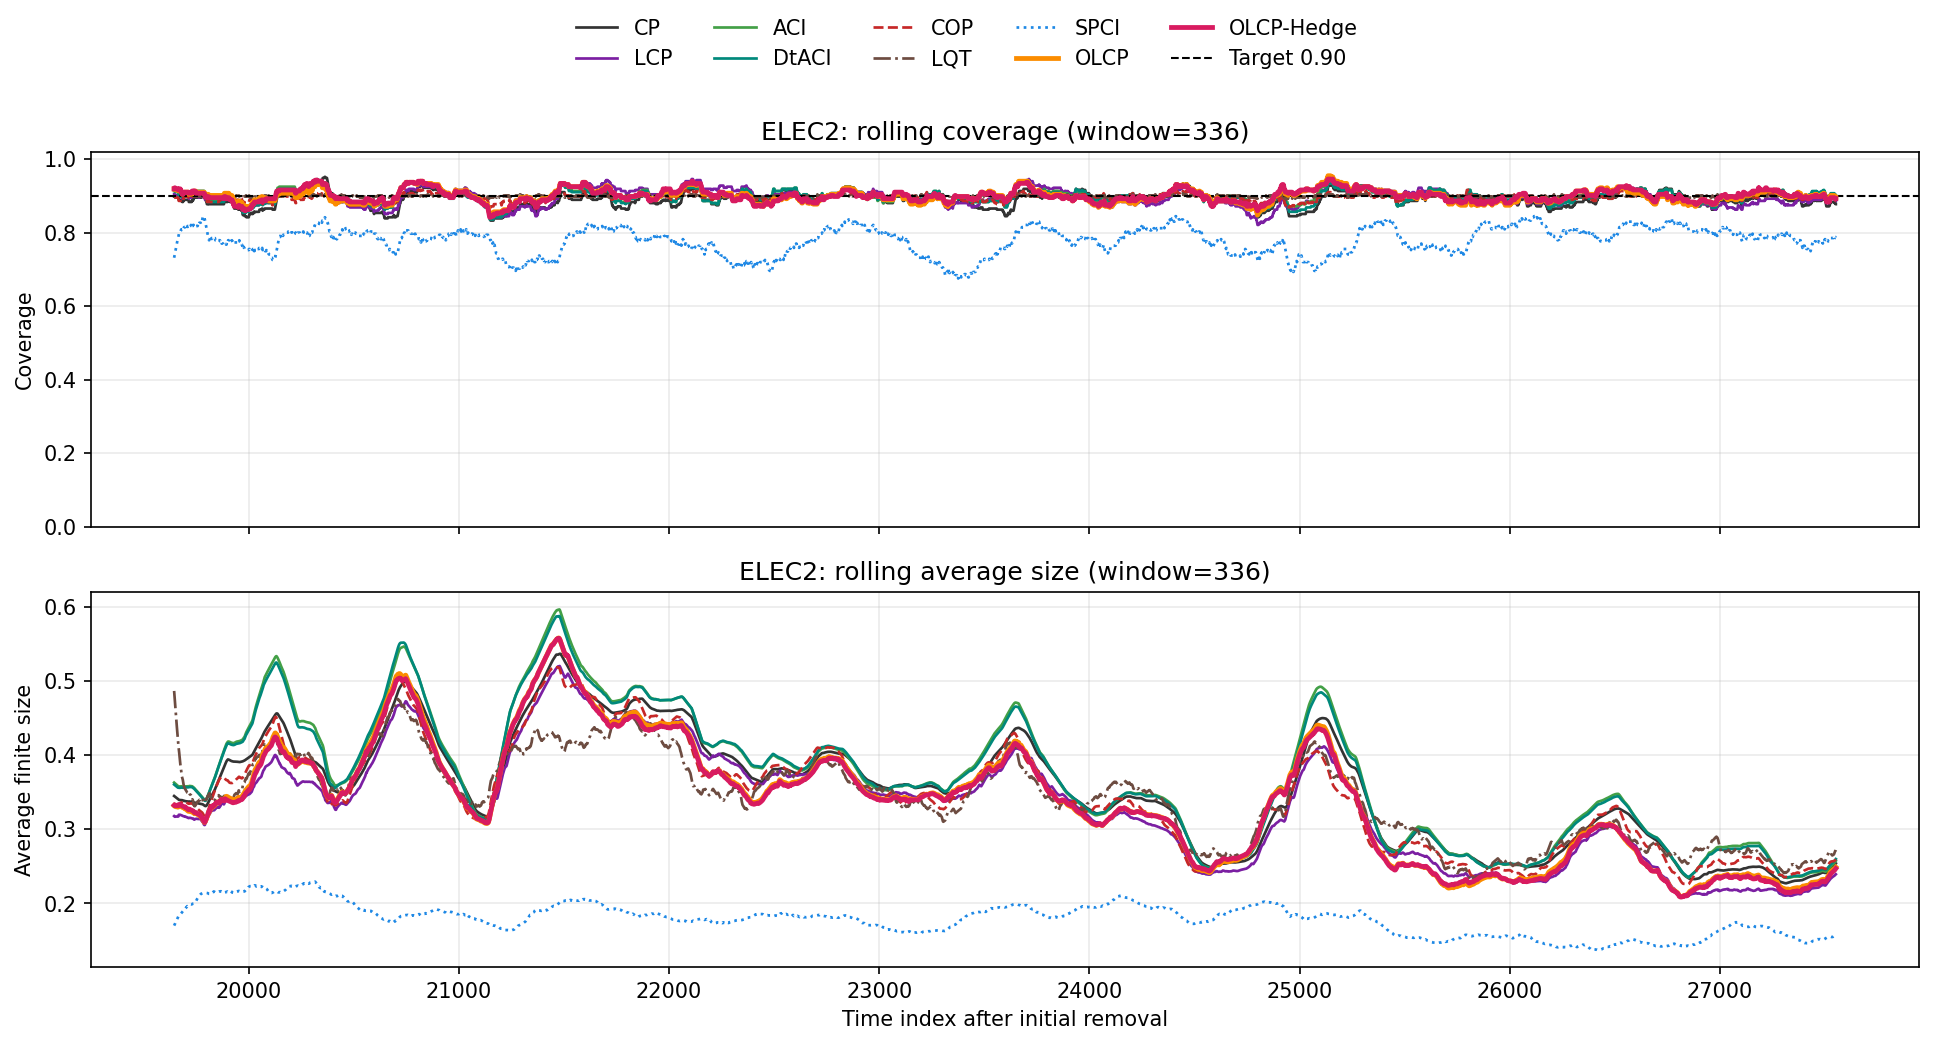

In [6]:
COLORS = dict(zip(METHOD_ORDER, [
    "#333333", "#7B1FA2", "#43A047", "#00897B", "#C62828",
    "#6D4C41", "#1E88E5", "#FB8C00", "#D81B60",
]))
LINESTYLES = {"cop": "--", "lqt": "-.", "spci": ":"}


def plot_rolling_diagnostics(results, window):
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    for name in METHOD_ORDER:
        frame = results[name]
        covered = frame["covered"].astype(float)
        finite_size = frame["width"].replace([np.inf, -np.inf], np.nan)
        rolling_coverage = covered.rolling(window, min_periods=window).mean()
        rolling_size = finite_size.rolling(window, min_periods=1).mean()
        start = window - 1
        for ax, values in zip(axes, (rolling_coverage, rolling_size)):
            ax.plot(
                frame["t"].iloc[start:], values.iloc[start:],
                label=LABELS[name], color=COLORS[name],
                linestyle=LINESTYLES.get(name, "-"),
                linewidth=2.3 if name in ("olcp", "olcph") else 1.3,
                zorder=4 if name in ("olcp", "olcph") else 2,
            )
    axes[0].axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1,
                    label=f"Target {1 - ALPHA:.2f}")
    axes[0].set_title(f"ELEC2: rolling coverage (window={window})")
    axes[0].set_ylabel("Coverage")
    axes[0].set_ylim(0, 1.02)
    axes[1].set_title(f"ELEC2: rolling average size (window={window})")
    axes[1].set_ylabel("Average finite size")
    axes[1].set_xlabel("Time index after initial removal")
    for ax in axes:
        ax.grid(alpha=0.25)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=5, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.91))
    return fig


fig = plot_rolling_diagnostics(results, ROLLING_WINDOW)
# Embed a portable static preview for GitHub without writing additional files.
image_buffer = io.BytesIO()
fig.savefig(image_buffer, format="png", dpi=150, bbox_inches="tight")
display(Image(data=image_buffer.getvalue()))
plt.close(fig)
